# Reto Global Classroom – Etapa 2: Extracción, limpieza y transformación de datos
**Ciudad:** Nueva York · **Fuente:** Inside Airbnb, `listings.csv.gz` (Detailed Listings data, recolección del 14–15 de septiembre de 2026)

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

RUTA = 'listings.csv.gz'
SALIDA = 'datos_limpios'
os.makedirs(SALIDA, exist_ok=True)

## 1. Análisis exploratorio de los datos iniciales

In [2]:
raw = pd.read_csv(RUTA, low_memory=False)
REF = pd.to_datetime(raw['last_scraped']).max()   # fecha de referencia (última recolección)
print(f'Filas: {raw.shape[0]:,} | Variables: {raw.shape[1]}')
print('Fechas de recolección:', raw['last_scraped'].value_counts().to_dict())
print('Identificadores duplicados:', raw['id'].duplicated().sum())

Filas: 29,918 | Variables: 90
Fechas de recolección: {'2026-09-15': 17993, '2026-09-14': 11925}
Identificadores duplicados: 0


In [3]:
def tipo(s):
    if pd.api.types.is_bool_dtype(s): return 'booleano'
    if pd.api.types.is_numeric_dtype(s): return 'numérico'
    return 'texto'

resumen = pd.DataFrame({
    'tipo': raw.apply(tipo),
    'dtype': raw.dtypes.astype(str),
    'nulos': raw.isna().sum(),
    'pct_nulos': (raw.isna().mean() * 100).round(1),
    'n_unicos': raw.nunique(),
})
resumen['tipo'].value_counts().rename('n_variables').to_frame()

,n_variables
tipo,
numérico,60
texto,30


In [4]:
resumen[resumen['nulos'] > 0].sort_values('pct_nulos', ascending=False)

,tipo,dtype,nulos,pct_nulos,n_unicos
host_since,numérico,float64,29918,100.0,0
neighborhood_overview,numérico,float64,29918,100.0,0
host_verifications,numérico,float64,29918,100.0,0
host_acceptance_rate,numérico,float64,29918,100.0,0
host_neighbourhood,numérico,float64,29918,100.0,0
host_total_listings_count,numérico,float64,29918,100.0,0
host_thumbnail_url,numérico,float64,29918,100.0,0
host_response_time,numérico,float64,29918,100.0,0
host_response_rate,numérico,float64,29918,100.0,0
neighbourhood,numérico,float64,29918,100.0,0


In [5]:
vacias = resumen.index[resumen['nulos'] == len(raw)].tolist()
constantes = [c for c in raw.columns if raw[c].nunique(dropna=False) == 1 and c not in vacias]
print(f'Variables 100% nulas ({len(vacias)}):', vacias)
print(f'Variables constantes ({len(constantes)}):', constantes)
print(f'Variables con algún nulo: {(resumen.nulos > 0).sum()} de {raw.shape[1]}')

Variables 100% nulas (13): ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'bathrooms', 'calendar_updated', 'instant_bookable']
Variables constantes (1): ['scrape_id']
Variables con algún nulo: 50 de 90


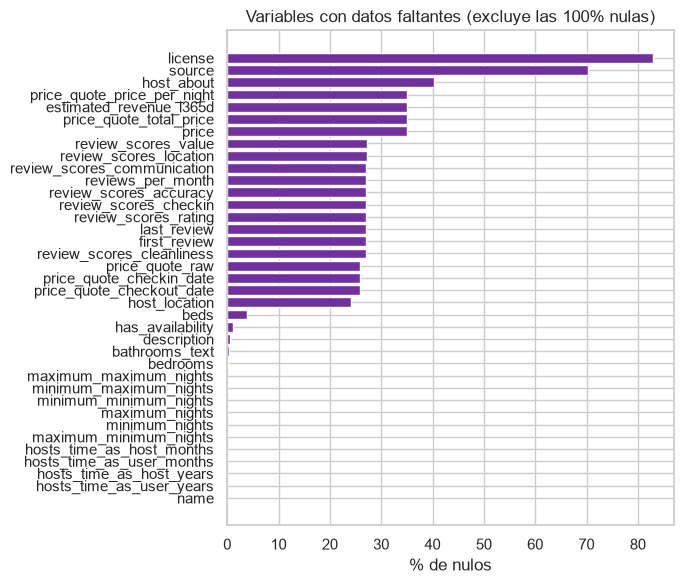

In [6]:
nul = resumen[(resumen.nulos > 0) & (resumen.nulos < len(raw))].sort_values('pct_nulos')
plt.figure(figsize=(7, 6))
plt.barh(nul.index, nul['pct_nulos'], color='#7030A0')
plt.xlabel('% de nulos'); plt.title('Variables con datos faltantes (excluye las 100% nulas)')
plt.tight_layout(); plt.show()

## 2. Preparación, limpieza y transformación

### 2.1 Variable objetivo: precio

In [7]:
df = raw.copy()
df['price'] = df['price'].str.replace(r'[$,]', '', regex=True).astype(float)
sin_precio = df['price'].isna()
print(f'Anuncios sin precio: {sin_precio.sum():,} ({sin_precio.mean():.1%})')
df.groupby(sin_precio.rename('sin_precio'))[['availability_365', 'number_of_reviews']].mean().round(1)

Anuncios sin precio: 10,512 (35.1%)


,availability_365,number_of_reviews
sin_precio,,
False,253.5,41.7
True,69.4,18.0


In [8]:
# El precio es la variable a predecir: no se imputa; se excluyen los anuncios sin precio
df = df[df['price'].notna()].copy()
print('Anuncios con precio:', df.shape[0])
df['price'].describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(1).to_frame().T

Anuncios con precio: 19406


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
price,19406.0,310.2,574.1,17.7,43.4,103.7,182.4,337.0,880.0,2000.0,31537.8


### 2.2 Eliminación de variables vacías y constantes

In [9]:
df = df.drop(columns=vacias + constantes)
print('Variables restantes:', df.shape[1])

Variables restantes: 76


### 2.3 Formatos y nuevas variables

In [10]:
# Booleanos t/f -> 1/0
for c in ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'has_availability']:
    df[c] = df[c].map({'t': 1, 'f': 0})

# Fechas -> días transcurridos hasta la fecha de recolección
for c in ['first_review', 'last_review']:
    df[c] = pd.to_datetime(df[c], errors='coerce')
df['dias_desde_primera_resena'] = (REF - df['first_review']).dt.days
df['dias_desde_ultima_resena'] = (REF - df['last_review']).dt.days
df['sin_resenas'] = (df['number_of_reviews'] == 0).astype(int)

# Baños: texto -> número y bandera de baño compartido
txt = df['bathrooms_text'].str.lower()
df['banos'] = pd.to_numeric(txt.str.extract(r'(\d+\.?\d*)')[0], errors='coerce')
df.loc[txt.str.contains('half', na=False) & df['banos'].isna(), 'banos'] = 0.5
df['banos_compartido'] = txt.str.contains('shared', na=False).astype(int)

# Anfitrión
df['host_local'] = df['host_location'].str.contains('new york', case=False, na=False).astype(int)
df['host_antiguedad_anios'] = df['hosts_time_as_host_years'] + df['hosts_time_as_host_months'] / 12

# Licencia
lic = df['license'].fillna('')
df['licencia'] = np.select([lic.eq(''), lic.str.lower().eq('exempt')], ['sin_licencia', 'exenta'], default='registrada')

# Distancia a Times Square (km, fórmula de Haversine)
def haversine(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))
df['distancia_centro_km'] = haversine(df['latitude'], df['longitude'], 40.7580, -73.9855)

# Tipo de propiedad: categorías con menos de 200 anuncios -> 'Other'
vc = df['property_type'].value_counts()
df['tipo_propiedad'] = df['property_type'].where(df['property_type'].map(vc) >= 200, 'Other')
df['tipo_propiedad'].value_counts().to_frame()

,count
tipo_propiedad,
Entire rental unit,7609
Private room in rental unit,4040
Private room in home,1984
Room in hotel,1632
Other,1148
Entire home,880
Private room in townhouse,571
Entire condo,561
Entire townhouse,276


In [11]:
# Comodidades: lista JSON -> conteo y banderas de las 20 más informativas (frecuencia cercana a 50 %)
df['amenities_lista'] = df['amenities'].apply(lambda s: [a.strip().lower() for a in json.loads(s)] if isinstance(s, str) else [])
df['n_amenities'] = df['amenities_lista'].str.len()
frec = pd.Series([a for l in df['amenities_lista'] for a in set(l)]).value_counts() / len(df)
print('Comodidades distintas:', len(frec))
top = (frec * (1 - frec)).sort_values(ascending=False).head(20).index
amen_cols = []
for a in top:
    nombre = 'amen_' + ''.join(ch if ch.isalnum() else '_' for ch in a).strip('_')
    df[nombre] = df['amenities_lista'].apply(lambda l: int(a in l))
    amen_cols.append(nombre)
frec[top].round(3).rename('frecuencia').to_frame()

Comodidades distintas: 4838


,frecuencia
self check-in,0.502
fire extinguisher,0.530
shampoo,0.544
first aid kit,0.448
long term stays allowed,0.433
tv,0.576
cooking basics,0.577
extra pillows and blankets,0.422
free street parking,0.417
microwave,0.592


### 2.4 Selección de variables relevantes

In [12]:
binarias = ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'has_availability',
            'banos_compartido', 'host_local', 'sin_resenas']
categoricas = ['neighbourhood_group_cleansed', 'neighbourhood_cleansed', 'room_type', 'tipo_propiedad', 'licencia']
numericas = ['accommodates', 'bedrooms', 'beds', 'banos', 'minimum_nights', 'maximum_nights',
             'availability_30', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'reviews_per_month',
             'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
             'review_scores_communication', 'review_scores_location', 'review_scores_value',
             'host_listings_count', 'calculated_host_listings_count', 'estimated_occupancy_l365d',
             'latitude', 'longitude', 'distancia_centro_km', 'host_antiguedad_anios', 'n_amenities',
             'dias_desde_primera_resena', 'dias_desde_ultima_resena'] + amen_cols

# Binarias casi constantes (>= 95 % en una categoría) no aportan información
casi_const = [c for c in binarias if df[c].value_counts(normalize=True).iloc[0] >= 0.95]
print('Binarias casi constantes:', casi_const)
binarias = [c for c in binarias if c not in casi_const]

# Numéricas con correlación > 0.9 (se conserva la primera de cada par)
corr = df[numericas].corr().abs()
pares = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(numericas) for b in numericas[i + 1:] if corr.loc[a, b] > 0.9]
print('Pares con |r| > 0.9:', pares)
redundantes = sorted({b for _, b, _ in pares})
numericas = [c for c in numericas if c not in redundantes]
print('Variables numéricas finales:', len(numericas))

Binarias casi constantes: ['host_has_profile_pic', 'host_identity_verified', 'has_availability']
Pares con |r| > 0.9: []
Variables numéricas finales: 48


In [13]:
# Variables descartadas por tipo de motivo
descartadas = {
    'Identificadores, enlaces y texto libre': ['listing_url', 'picture_url', 'host_url', 'host_profile_id', 'host_profile_url',
        'host_name', 'host_picture_url', 'name', 'description', 'host_about', 'host_location', 'license', 'amenities',
        'amenities_lista', 'property_type', 'bathrooms_text', 'source', 'last_scraped', 'calendar_last_scraped'],
    'Derivan del precio (fuga de información)': [c for c in raw.columns if c.startswith('price_quote_')] + ['estimated_revenue_l365d'],
    'Redundantes con otras variables': ['minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights',
        'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_60', 'availability_90',
        'availability_eoy', 'number_of_reviews_ly', 'number_of_reviews_l30d', 'calculated_host_listings_count_entire_homes',
        'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms',
        'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months',
        'first_review', 'last_review'] + casi_const + redundantes,
}
pd.Series({k: len(v) for k, v in descartadas.items()}, name='n_variables').to_frame()

,n_variables
"Identificadores, enlaces y texto libre",19
Derivan del precio (fuga de información),6
Redundantes con otras variables,23


In [14]:
columnas = ['id', 'price'] + categoricas + binarias + numericas
df = df[columnas].copy()
print('Variables conservadas:', df.shape[1], '| Filas:', df.shape[0])

Variables conservadas: 59 | Filas: 19406


### 2.5 Valores faltantes

In [15]:
nulos = df.isna().sum()
nulos[nulos > 0].to_frame('nulos').assign(pct=lambda x: (x.nulos / len(df) * 100).round(2))

,nulos,pct
bedrooms,32,0.16
beds,909,4.68
banos,100,0.52
minimum_nights,7,0.04
maximum_nights,7,0.04
reviews_per_month,5068,26.12
review_scores_rating,5068,26.12
review_scores_accuracy,5068,26.12
review_scores_cleanliness,5068,26.12
review_scores_checkin,5068,26.12


In [16]:
# Estrategia por variable
# - banos, bedrooms, beds: mediana por tipo de alojamiento
for c in ['banos', 'bedrooms', 'beds']:
    df[c] = df[c].fillna(df.groupby('room_type')[c].transform('median')).fillna(df[c].median())

# - calificaciones: 0 no es una calificación válida (escala 1-5); sin reseñas -> mediana + bandera sin_resenas
cols_score = [c for c in df.columns if c.startswith('review_scores_')]
df[cols_score] = df[cols_score].replace(0, np.nan)
cols_mediana = cols_score + ['dias_desde_primera_resena', 'dias_desde_ultima_resena']
df[cols_mediana] = df[cols_mediana].fillna(df[cols_mediana].median())

# - reviews_per_month: sin reseñas equivale a 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# - resto de numéricas con pocos nulos: mediana; binarias: moda
for c in ['host_antiguedad_anios', 'minimum_nights', 'maximum_nights']:
    df[c] = df[c].fillna(df[c].median())
for c in binarias:
    df[c] = df[c].fillna(df[c].mode()[0])

print('Nulos restantes:', int(df.isna().sum().sum()))

Nulos restantes: 0


### 2.6 Formato de variables categóricas

In [17]:
for c in categoricas:
    df[c] = df[c].astype(str).str.strip()
pd.DataFrame({
    'n_categorias': df[categoricas].nunique(),
    'n_sin_distinguir_mayusculas': df[categoricas].apply(lambda s: s.str.lower().nunique()),
})

,n_categorias,n_sin_distinguir_mayusculas
neighbourhood_group_cleansed,5,5
neighbourhood_cleansed,223,223
room_type,4,4
tipo_propiedad,12,12
licencia,3,3


In [18]:
# Barrios con menos de 100 anuncios se agrupan en 'Other' para la codificación
vc = df['neighbourhood_cleansed'].value_counts()
df['barrio_agrupado'] = df['neighbourhood_cleansed'].where(df['neighbourhood_cleansed'].map(vc) >= 100, 'Other')
print('Barrios originales:', df['neighbourhood_cleansed'].nunique(), '| Agrupados:', df['barrio_agrupado'].nunique())

Barrios originales: 223 | Agrupados: 45


### 2.7 Análisis y tratamiento de outliers

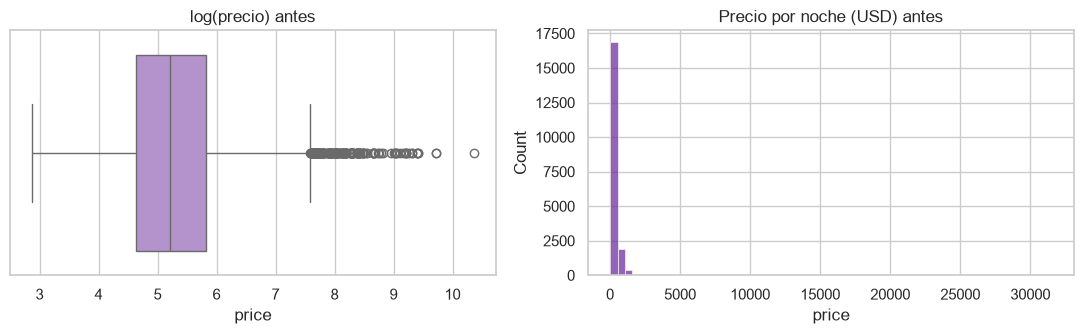

,count,mean,std,min,50%,95%,99%,99.9%,max
price,19406.0,310.2,574.1,17.7,182.4,880.0,2000.0,8269.1,31537.8


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=np.log(df['price']), ax=ax[0], color='#B58AD6'); ax[0].set_title('log(precio) antes')
sns.histplot(df['price'], bins=60, ax=ax[1], color='#7030A0'); ax[1].set_title('Precio por noche (USD) antes')
plt.tight_layout(); plt.show()
df['price'].describe(percentiles=[.5, .95, .99, .999]).round(1).to_frame().T

In [20]:
# Precio: método IQR (1.5) sobre log(precio), por la fuerte asimetría
lp = np.log(df['price'])
q1, q3 = lp.quantile([.25, .75])
lim_inf, lim_sup = np.exp(q1 - 1.5 * (q3 - q1)), np.exp(q3 + 1.5 * (q3 - q1))
fuera = (df['price'] < lim_inf) | (df['price'] > lim_sup)
print(f'Límites: {lim_inf:.1f} a {lim_sup:.1f} USD | Anuncios fuera: {fuera.sum()} ({fuera.mean():.1%})')
df = df[~fuera].copy()
df['log_price'] = np.log(df['price'])
print('Filas finales:', df.shape[0])

Límites: 17.7 a 1974.8 USD | Anuncios fuera: 203 (1.0%)
Filas finales: 19203


In [21]:
# Otras numéricas: valores centinela y colas extremas
print('maximum_nights > 1125 (límite de la plataforma):', (df['maximum_nights'] > 1125).sum(),
      '| máximo:', int(df['maximum_nights'].max()))
df['maximum_nights'] = df['maximum_nights'].clip(upper=1125)
df['minimum_nights'] = df['minimum_nights'].clip(upper=365)

# Conteos con colas largas: se recortan en el percentil 99
cols_p99 = ['beds', 'bedrooms', 'banos', 'host_listings_count', 'calculated_host_listings_count',
            'number_of_reviews', 'number_of_reviews_ltm', 'reviews_per_month', 'estimated_occupancy_l365d']
antes = df[cols_p99].max()
tope = df[cols_p99].quantile(.99)
df[cols_p99] = df[cols_p99].clip(upper=tope, axis=1)
pd.DataFrame({'max_antes': antes, 'tope_p99': tope, 'max_despues': df[cols_p99].max()}).round(2)

maximum_nights > 1125 (límite de la plataforma): 26 | máximo: 2147483647


,max_antes,tope_p99,max_despues
beds,20.00,6.00,6.00
bedrooms,9.00,4.00,4.00
banos,10.50,3.00,3.00
host_listings_count,5711.00,5711.00,5711.00
calculated_host_listings_count,889.00,330.00,330.00
number_of_reviews,4894.00,409.00,409.00
number_of_reviews_ltm,1174.00,79.00,79.00
reviews_per_month,146.87,7.67,7.67
estimated_occupancy_l365d,255.00,255.00,255.00


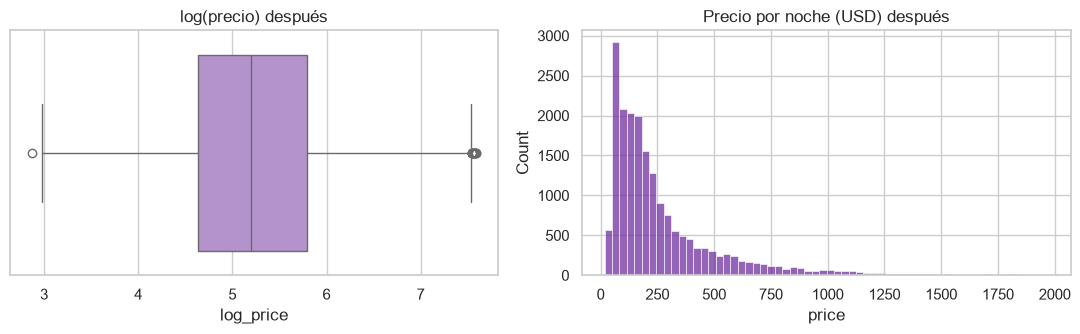

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df['log_price'], ax=ax[0], color='#B58AD6'); ax[0].set_title('log(precio) después')
sns.histplot(df['price'], bins=60, ax=ax[1], color='#7030A0'); ax[1].set_title('Precio por noche (USD) después')
plt.tight_layout(); plt.show()

### Hallazgo para las etapas siguientes: estancia mínima

In [23]:
larga = df['minimum_nights'] >= 30
print(f'Anuncios con estancia mínima de 30 noches o más: {larga.mean():.1%}')
df.groupby(larga.rename('minimo_30_noches_o_mas'))['price'].agg(['count', 'median']).round(1)

Anuncios con estancia mínima de 30 noches o más: 73.8%


,count,median
minimo_30_noches_o_mas,,
False,5033,370.0
True,14170,145.6


## 3. Codificación

In [24]:
cat_cod = ['neighbourhood_group_cleansed', 'barrio_agrupado', 'room_type', 'tipo_propiedad', 'licencia']
codificado = pd.get_dummies(df.drop(columns=['neighbourhood_cleansed']), columns=cat_cod, drop_first=True, dtype=int)
print('Variables codificadas:', codificado.shape[1], '| Filas:', codificado.shape[0])
print('Tipos:', codificado.dtypes.astype(str).value_counts().to_dict())

Variables codificadas: 119 | Filas: 19203
Tipos: {'int64': 98, 'float64': 21}


## 4. Verificación y guardado

In [25]:
verif = {
    'Nulos en el conjunto limpio': int(df.isna().sum().sum()),
    'Nulos en el conjunto codificado': int(codificado.isna().sum().sum()),
    'Variables no numéricas en el codificado': int((~codificado.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
    'Conjunto limpio (filas x variables)': f'{df.shape[0]:,} x {df.shape[1]}',
    'Conjunto codificado (filas x variables)': f'{codificado.shape[0]:,} x {codificado.shape[1]}',
    'Identificadores duplicados': int(df['id'].duplicated().sum()),
    'Precio mínimo / máximo (USD)': f"{df['price'].min():.1f} / {df['price'].max():.1f}",
}
pd.Series(verif, name='valor').to_frame()

,valor
Nulos en el conjunto limpio,0
Nulos en el conjunto codificado,0
Variables no numéricas en el codificado,0
Conjunto limpio (filas x variables),"19,203 x 61"
Conjunto codificado (filas x variables),"19,203 x 119"
Identificadores duplicados,0
Precio mínimo / máximo (USD),17.7 / 1972.0


In [26]:
desc = {
    'id': 'Identificador del anuncio', 'price': 'Precio por noche (USD) – variable objetivo', 'log_price': 'Logaritmo natural del precio',
    'neighbourhood_group_cleansed': 'Municipio (borough)', 'neighbourhood_cleansed': 'Barrio', 'barrio_agrupado': 'Barrio (los de menos de 100 anuncios agrupados en Other)',
    'room_type': 'Tipo de alojamiento', 'tipo_propiedad': 'Tipo de propiedad (categorías con menos de 200 anuncios agrupadas en Other)',
    'licencia': 'Estado de la licencia: sin_licencia, exenta o registrada',
    'host_is_superhost': 'Anfitrión Superhost (1/0)', 'banos_compartido': 'Baño compartido (1/0)',
    'host_local': 'Anfitrión ubicado en Nueva York (1/0)', 'sin_resenas': 'Anuncio sin reseñas (1/0)',
    'accommodates': 'Capacidad de huéspedes', 'bedrooms': 'Número de habitaciones', 'beds': 'Número de camas', 'banos': 'Número de baños',
    'minimum_nights': 'Mínimo de noches (máx. 365)', 'maximum_nights': 'Máximo de noches (máx. 1125)',
    'availability_30': 'Días disponibles en los próximos 30', 'availability_365': 'Días disponibles en los próximos 365',
    'number_of_reviews': 'Número total de reseñas', 'number_of_reviews_ltm': 'Reseñas en los últimos 12 meses', 'reviews_per_month': 'Reseñas por mes',
    'host_listings_count': 'Anuncios del anfitrión', 'calculated_host_listings_count': 'Anuncios del anfitrión (calculado en Nueva York)',
    'estimated_occupancy_l365d': 'Ocupación estimada, últimos 365 días (noches)',
    'latitude': 'Latitud', 'longitude': 'Longitud', 'distancia_centro_km': 'Distancia a Times Square (km)',
    'host_antiguedad_anios': 'Antigüedad del anfitrión (años)', 'n_amenities': 'Número de comodidades',
    'dias_desde_primera_resena': 'Días desde la primera reseña', 'dias_desde_ultima_resena': 'Días desde la última reseña',
}
for c in cols_score:
    desc[c] = 'Calificación (1–5): ' + c.replace('review_scores_', '')
for c in amen_cols:
    desc[c] = 'Ofrece la comodidad "' + c.replace('amen_', '').replace('_', ' ') + '" (1/0)'
sin_desc = [c for c in df.columns if c not in desc]
print('Variables sin descripción:', sin_desc)
diccionario = pd.DataFrame({'variable': df.columns, 'tipo': ['categórica' if c in categoricas + ['barrio_agrupado'] else 'numérica' for c in df.columns],
                            'descripcion': [desc.get(c, '') for c in df.columns]})
df.to_csv(f'{SALIDA}/airbnb_nyc_limpio.csv', index=False)
codificado.to_csv(f'{SALIDA}/airbnb_nyc_codificado.csv', index=False)
diccionario.to_csv(f'{SALIDA}/diccionario_variables.csv', index=False)
print('Guardado en', SALIDA, '->', os.listdir(SALIDA))

Variables sin descripción: []
Guardado en datos_limpios -> ['airbnb_nyc_codificado.csv', 'airbnb_nyc_limpio.csv', 'diccionario_variables.csv']
